# Reading an Exodus II finite-element mesh

**Exodus II** is the Sandia/Trilinos finite-element model and results format, stored as NetCDF (CDF-2) underneath. It is the interchange format for libMesh, MOOSE, Sierra and much of the Trilinos ecosystem. `pyramids-mesh` reads the mesh into a `pyramids.netcdf.ugrid.UgridDataset`.

This sample is a libMesh test mesh, `nontrivial_node_num_map.exo` — a small, clean **planar QUAD4** mesh (4 cells, 9 nodes) with a non-trivial node-numbering map, which the reader resolves transparently (LGPL-licensed data). The directory also holds `geom_2.exo`, a 3-D TETRA mesh.

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

## 3. Locate the example data

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. Paths inside a notebook are written **relative to the notebook itself**. The critical rule for `read_file` is to pass a `pathlib.Path`, never `str(...)`. We read `exodus/nontrivial_node_num_map.exo`.

In [2]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "exodus" / "nontrivial_node_num_map.exo"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/exodus/nontrivial_node_num_map.exo'), True)

## 4. Quickstart: read the file

`UgridDataset.read_file(path, driver=...)` parses the file and returns a `UgridDataset` — the same type pyramids produces from a NetCDF UGRID file. We name the `"exodus"` driver explicitly; passing the **`Path`** object (not a string) is the supported call.

In [3]:
ds = UgridDataset.read_file(mesh_file, driver="exodus")
type(ds).__name__

'UgridDataset'

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## 5. Explore the dataset

A `UgridDataset` exposes summary properties: `n_node` / `n_face` (mesh size), `crs` / `epsg` (georeferencing if the format recorded any), `bounds` (the `(minx, miny, maxx, maxy)` extent), and `data_variable_names` (attached field variables).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": tuple(round(float(b), 3) for b in ds.bounds),
    "data_variable_names": ds.data_variable_names,
})

n_node                                      9
n_face                                      4
crs                                      None
epsg                                     None
bounds                 (-0.5, -0.5, 0.5, 0.5)
data_variable_names                        []
dtype: object

`crs`/`epsg` are `None`: a finite-element mesh carries no geographic CRS. This is a tiny 4-cell QUAD4 patch on `(-0.5, -0.5, 0.5, 0.5)`. `data_variable_names` is empty — pure topology; the non-trivial node-number map in the file has already been applied, so indices are contiguous here.

## 6. Face-degree distribution

`ds.mesh.face_node_connectivity.data` is the `(n_face, k)` table of node indices per face, where `k` is the widest polygon. Cells with fewer nodes than `k` are **padded with `-1` (fill)**. Counting the non-negative entries per row gives each face's number of nodes — its *degree*.

In [6]:
conn = ds.mesh.face_node_connectivity.data
degree = (conn >= 0).sum(axis=1)
vals, counts = np.unique(degree, return_counts=True)
dist = pd.Series(dict(zip(vals.tolist(), counts.tolist())), name="n_faces")
dist.index.name = "nodes_per_face"
{"degree_distribution": dist.to_dict(), "fill_slots(-1)": int((conn == -1).sum())}

{'degree_distribution': {4: 4}, 'fill_slots(-1)': 0}

All 4 cells have **4 nodes** with no `-1` fill — QUAD4 elements. Exodus also stores 3-D element types (TETRA, HEX, ...); the sibling `geom_2.exo` is a tetrahedral mesh that would show degree-4 tets and a `node_z` field instead.

## 7. The underlying geometry

`ds.mesh` is the `Mesh2d` holding the raw arrays: `node_x` / `node_y` (coordinates), the connectivity table, `face_areas` (one area per cell) and `face_centroids` (shape `(2, n_face)`). Everything geometric is derived from the connectivity plus the node coordinates.

In [7]:
mesh = ds.mesh
conn = mesh.face_node_connectivity.data
areas = mesh.face_areas
cent = np.asarray(mesh.face_centroids)  # (2, n_face)
{"conn_shape": conn.shape, "n_node": mesh.node_x.shape[0],
 "areas_minmax": (round(float(areas.min()), 4), round(float(areas.max()), 4)),
 "centroids_shape": cent.shape}

{'conn_shape': (4, 4),
 'n_node': 9,
 'areas_minmax': (0.25, 0.25),
 'centroids_shape': (2, 4)}

## 8. Wireframe: `plot_outline()`

The simplest view needs no data — just the mesh edges. `plot_outline()` draws the wireframe through cleopatra and embeds it inline. This is the fastest sanity check that a file read in correctly.

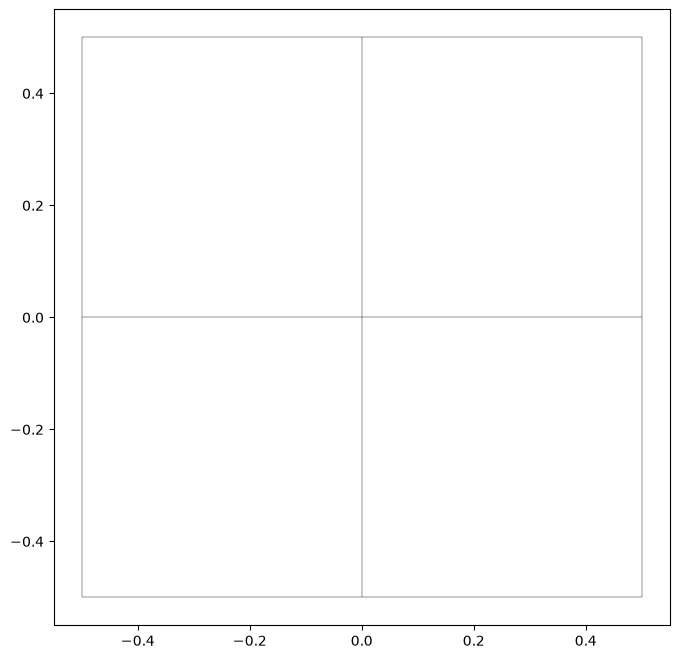

In [8]:
ds.plot_outline()


Four unit quads meeting at the origin — the 2x2 QUAD4 patch exactly as stored. Each cell has area 0.25, a clean check that the node-number map was resolved correctly.

## 9. A data map: attach and colour a field

To draw a *filled* map we need a value per cell. These mesh files carry geometry only, so we compute one — each cell's area — and attach it with `with_variable(..., location="face")`, which returns a **new** dataset (the original `ds` is untouched). Then `plot` colours the mesh by it.

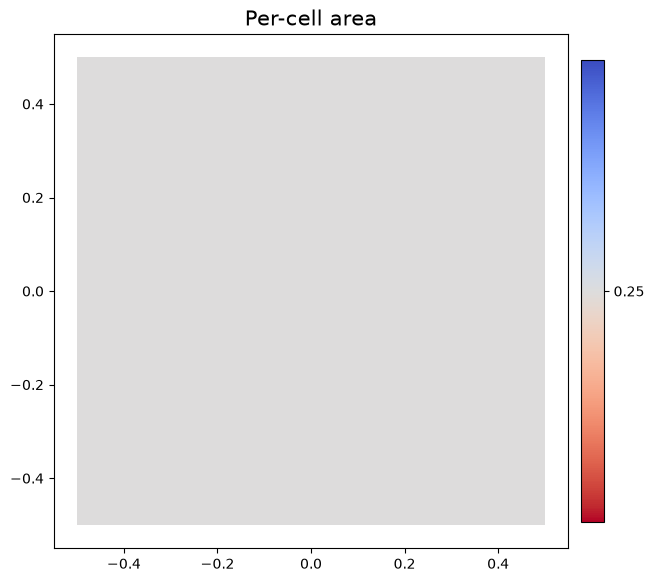

In [9]:
d2 = ds.with_variable("cell_area", ds.mesh.face_areas, location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="Per-cell area")


Each cell is now shaded by its area. This is the generic pyramids data-map path — any per-cell field (water depth, velocity, head) plots exactly the same way.

### The statistical summary

With a field attached, `.summary()` reports per-variable statistics (count, min, max, mean, std). On the bare `ds` it is an empty frame; on `d2` it has a real row.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
cell_area,4,0.25,0.25,0.25,0.0


## 10. GIS operations, for free

Because the mesh is now a first-class pyramids object, the pyramids GIS layer applies directly — `pyramids-mesh` itself adds none of this. The next cells each run one operation and interpret it.

### Faces as a GeoDataFrame

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((0.5 -0.5, 0.5 0, 0 0, 0 -0.5, 0.5 -0..."
1,"POLYGON ((0.5 0, 0.5 0.5, 0 0.5, 0 0, 0.5 0))"
2,"POLYGON ((0 -0.5, 0 0, -0.5 0, -0.5 -0.5, 0 -0..."
3,"POLYGON ((0 0, 0 0.5, -0.5 0.5, -0.5 0, 0 0))"


Plotting that GeoDataFrame draws the mesh footprint as vector polygons (one patch per cell).

<Axes: xlabel='x', ylabel='y'>

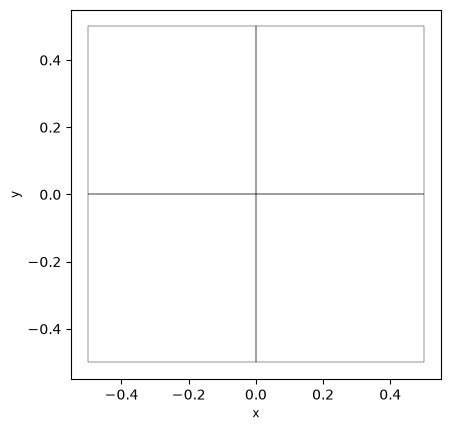

In [12]:
gdf.plot(edgecolor="black", facecolor="none", linewidth=0.3)


### Bounding polygon

`bounding_polygon()` dissolves the cells into a single shapely polygon of the meshed footprint — the gateway to the shapely/geopandas ecosystem for clipping and spatial joins.

In [13]:
poly = ds.bounding_polygon()
poly.geom_type, tuple(round(float(b), 3) for b in poly.bounds)

('Polygon', (-0.5, -0.5, 0.5, 0.5))

### Circumcenters — explain and skip

`circumcenters()` is **only defined for triangular meshes**. This mesh is not all-triangle, so the call raises `ValueError`; we catch it rather than crash. (Use cell centroids instead for such grids.)

In [14]:
try:
    ds.circumcenters()
except ValueError as e:
    print("skipped circumcenters:", e)

skipped circumcenters: circumcenters is only defined for triangular meshes.


### Exterior edges

`exterior_edges()` returns the node indices of the mesh **boundary** — the edges that belong to exactly one cell. Its length is a quick measure of how much perimeter the mesh has.

In [15]:
edges = ds.exterior_edges()
edges.shape, edges[:6].tolist()

((8,), [0, 3, 4, 5, 8, 9])

8 boundary-edge entries trace the outer square of the 2x2 patch — the four outer edges of the four quads. The interior cross edges, each shared by two cells, are excluded.

### Cell adjacency and connected components

`sparse_adjacency()` is the cell-to-cell adjacency as a SciPy sparse matrix (`nnz` = twice the number of shared internal edges). `connected_components()` labels which cells are mutually reachable through that adjacency.

In [16]:
adj = ds.sparse_adjacency()
labels = ds.connected_components()
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(labels).size)}

{'adjacency_shape': (4, 4), 'nnz': 8, 'n_components': 1}

A single connected component: all four quads share edges at the central cross, so the patch is one contiguous piece. `nnz` counts the internal neighbour links.

### Subset by a bounding box

`subset_by_bounds(xmin, ymin, xmax, ymax)` keeps only the cells inside a window (note the four positional coordinates, not a tuple). We take the centred 60% window and plot the result — a clean clip that returns a new `UgridDataset`. (`crop(bbox=...)` does the same thing with a tuple argument.)

In [17]:
b = ds.bounds
cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
hx, hy = (b[2] - b[0]) * 0.3, (b[3] - b[1]) * 0.3
sub = ds.subset_by_bounds(cx - hx, cy - hy, cx + hx, cy + hy)
{"full_n_face": ds.n_face, "subset_n_face": sub.n_face}

{'full_n_face': 4, 'subset_n_face': 4}

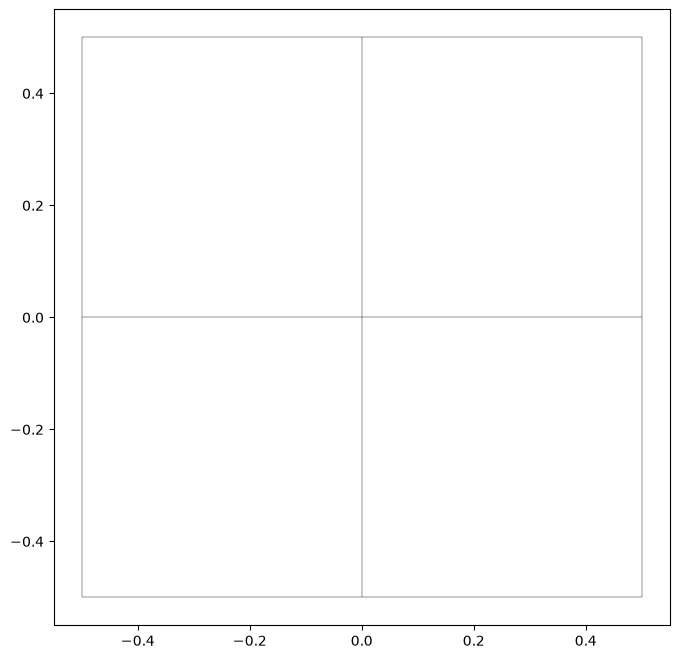

In [18]:
sub.plot_outline()


With only four cells meeting at the origin, every cell touches a centred window, so the subset keeps all four — the operation runs and returns a valid `UgridDataset`, it is just too small a mesh to carve up.

### Export: xarray and NetCDF round-trip

`to_xarray()` hands back an `xarray.Dataset` (the UGRID representation), and `to_file(path)` writes a NetCDF UGRID file — the canonical pyramids on-disk form that any UGRID reader can load back.

In [19]:
import tempfile, os
xds = ds.to_xarray()
out = os.path.join(tempfile.gettempdir(), "mesh_roundtrip.nc")
ds.to_file(out)
{"xarray_type": type(xds).__name__, "nc_bytes": os.path.getsize(out)}

{'xarray_type': 'Dataset', 'nc_bytes': 13144}

## 11. CRS-dependent operations — explain and skip

This format records **no CRS** (`crs` / `epsg` were `None` above), so coordinate-aware steps have nothing to work from:

- **`to_crs(...)`** — a reprojection needs a *source* CRS; with `None` there is nothing to reproject from, so we skip it. In practice you would first assign the CRS you know the model used.
- **`rasterize_like(...)` / `regrid(...)`** — these burn the mesh onto, or resample it to, a target **raster grid**. That is the job of the `pyramids-gis` raster layer (you supply a target `Dataset`); it is out of scope for a format-reader tutorial, so we only name it here.

In [20]:
ds.crs  # None -> no reprojection target; to_crs / rasterize_like / regrid skipped

## 12. Takeaway

- **Exodus II `.exo` = Trilinos/libMesh FE interchange format** (NetCDF underneath), read into a `UgridDataset`.
- This sample is a clean planar QUAD4 patch (degree 4, no `-1` fill) with a non-trivial node map resolved on read; `geom_2.exo` in the same folder is the 3-D TETRA counterpart.
- Quads, so `circumcenters()` is skipped; no CRS, so reprojection/rasterisation are skipped.
- Explore, plot and the full GIS toolbox apply to the FE mesh as to any `UgridDataset`.